# AML · 03 XGBoost Model
**Train, compare, explain, save and reload XGBoost against simple baselines.**

Run after `02_preprocessing.ipynb`, or set `RETRAIN = False` in section 2 to use the trained model already saved in `AML/Models/`.

Task: regression of the source-defined `CCME_Values` index (0–100).

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Imports and evaluation functions

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image
import random, platform, time
from datetime import UTC, datetime
from importlib.metadata import version
import joblib
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor, DMatrix
# Locate the repository root from either the repo root or the notebook folder.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "Datasets" / "Water_Quality_Dataset.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
PART = ROOT / "AML"              # This part of the project
DATA = ROOT / "Datasets"            # Shared source data
CACHE = DATA / "_working"           # Shared extracted CSV; ignored by Git
WORK = PART / "_working"            # Intermediate files for this part; ignored by Git
FIGURES = PART / "figures"
MODELS = PART / "Models"
RESULTS = PART / "Results"
for folder in [CACHE, WORK, FIGURES, MODELS, RESULTS]:
    folder.mkdir(exist_ok=True)
CSV = CACHE / "Combined_dataset.csv"
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = ["Ammonia", "BOD", "Dissolved oxygen", "Orthophosphate", "pH", "Temperature", "Nitrogen", "Nitrate"]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]
BANDS = ["Poor", "Marginal", "Fair", "Good", "Excellent"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_csv():
    """Extract the unmodified Figshare CSV from the shared ZIP once, then verify it."""
    if not CSV.exists():
        archive = DATA / "Water_Quality_Dataset.zip"
        if archive.exists():
            import shutil
            with zipfile.ZipFile(archive) as z, z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        else:
            import urllib.request
            urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
    assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
    return CSV


def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result


def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for review, not converted. Every input gets a
    fixed missing/invalid flag, so the model always receives 16 columns.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)


def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

def metrics(y, prediction):
    return {
        "mae": float(mean_absolute_error(y, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(y, prediction))),
        "r2": float(r2_score(y, prediction)),
    }

def residual_quantile(y, prediction, alpha=0.1):
    """Finite-sample-corrected quantile of held-out absolute residuals."""
    residual = np.abs(np.asarray(y) - np.asarray(prediction))
    rank = int(np.ceil((len(residual) + 1) * (1 - alpha)))
    if rank > len(residual):
        return float("inf")
    return float(np.partition(residual, rank - 1)[rank - 1])

def intervals(prediction, radius):
    return np.clip(prediction - radius, 0, 100), np.clip(prediction + radius, 0, 100)

def interval_metrics(y, prediction, radius):
    lower, upper = intervals(prediction, radius)
    return {
        "coverage": float(np.mean((y >= lower) & (y <= upper))),
        "mean_width": float(np.mean(upper - lower)),
        "radius": radius,
    }

def sample(frame, cap, seed):
    if cap and len(frame) > cap:
        return frame.sample(n=cap, random_state=seed).sort_index()
    return frame

## 2. Load prepared inputs or the saved model
Training uses the seed-42 sample of 300,000 pre-2019 rows. CPU threads are fixed at four.

In [2]:
# True: reproduce training after running 01 and 02.
# False: inspect the saved results and predict with the saved model immediately.
RETRAIN = True
if RETRAIN:
    bundle = joblib.load(WORK / "prepared.joblib")
    config = bundle["config"]
    train, tuning, splits = bundle["train"], bundle["tuning"], bundle["splits"]
    audit, manifest = bundle["audit"], bundle["manifest"]
    tree_pre, linear_pre = bundle["tree_pre"], bundle["linear_pre"]
    xt, xvt, xl, xvl = [bundle[k] for k in ["xt", "xvt", "xl", "xvl"]]
    y, yv = bundle["y"], bundle["yv"]
    random.seed(config["seed"]); np.random.seed(config["seed"])
    start = time.perf_counter()
else:
    assert (MODELS / "xgboost.json").exists(), "No saved model found in AML/Models/."
    print("Using the saved XGBoost model and measured results.")

## 3. XGBoost: gradient-boosted decision trees
Boosted trees handle thresholds and interactions without input scaling. Histogram trees, depth control, row subsampling, L2 regularization and validation early stopping constrain fitting. We compare depths 4 and 6, up to 1,000 rounds, learning rate 0.05 and patience 40.

In [3]:
if RETRAIN:
    candidates, histories = [], {}
    best_xgb, best_xgb_score = None, float("inf")
    for depth in config["xgb_depths"]:
        print(f"Training XGBoost, depth {depth}...", flush=True)
        tick = time.perf_counter()
        model = XGBRegressor(
            n_estimators=config["xgb_estimators"], max_depth=depth, learning_rate=0.05,
            min_child_weight=5, subsample=0.9, colsample_bytree=1.0, reg_lambda=5,
            tree_method="hist", max_bin=256, objective="reg:squarederror", eval_metric="rmse",
            early_stopping_rounds=40, random_state=config["seed"], n_jobs=config["threads"],
        )
        model.fit(xt, y, eval_set=[(xvt, yv)], verbose=200)
        score = metrics(yv, np.clip(model.predict(xvt), 0, 100))
        candidates.append({"family": "XGBoost", "architecture": f"depth {depth}", **score,
                           "seconds": time.perf_counter() - tick, "best_step": int(model.best_iteration + 1)})
        histories[f"XGBoost_depth_{depth}"] = model.evals_result()["validation_0"]["rmse"]
        if score["rmse"] < best_xgb_score:
            best_xgb, best_xgb_score, best_depth = model, score["rmse"], depth
    display(pd.DataFrame(candidates))

Training XGBoost, depth 4...


[0]	validation_0-rmse:12.86652


[200]	validation_0-rmse:0.56825


[400]	validation_0-rmse:0.51035


[600]	validation_0-rmse:0.49519


[800]	validation_0-rmse:0.48454


... (5 outputs left out)

[600]	validation_0-rmse:0.45468


[800]	validation_0-rmse:0.45282


[842]	validation_0-rmse:0.45299


,family,architecture,mae,rmse,r2,seconds,best_step
0,XGBoost,depth 4,0.138064,0.478137,0.998398,2.277621,999
1,XGBoost,depth 6,0.119844,0.452701,0.998564,2.428994,803


## 4. Baselines and validation selection
A training-mean baseline checks whether learning helps at all; Ridge regression (alpha 10) is a simple regularized linear reference. All three are scored on the full 2019 validation year. The test set never selects a model.

In [4]:
if RETRAIN:
    pd.DataFrame(candidates).to_csv(RESULTS / "validation_candidates.csv", index=False)
    dump_json(RESULTS / "training_history.json", histories)
    dummy = DummyRegressor(strategy="mean").fit(xt, y)
    ridge = Ridge(alpha=10).fit(xl, y)
    models = {
        "Mean baseline": lambda frame: dummy.predict(tree_pre.transform(frame)),
        "Ridge": lambda frame: np.clip(ridge.predict(linear_pre.transform(frame)), 0, 100),
        "XGBoost": lambda frame: np.clip(best_xgb.predict(tree_pre.transform(frame)), 0, 100),
    }
    val_full_x = quality_features(splits["validation"])
    val_full_y = splits["validation"][TARGET].to_numpy()
    validation_scores = {name: metrics(val_full_y, predict(val_full_x)) for name, predict in models.items()}
    champion = min(validation_scores, key=lambda name: validation_scores[name]["rmse"])
    display(pd.DataFrame(validation_scores).T)
    print(f"Validation-selected model: {champion} (depth {best_depth})")

,mae,rmse,r2
Mean baseline,11.573003,13.461587,-0.274717
Ridge,4.304657,5.567674,0.781944
XGBoost,0.120056,0.452033,0.998563


Validation-selected model: XGBoost (depth 6)


## 5. Frozen test evaluation and residual intervals
Report MAE, RMSE and R² on all 202,886 held-out rows (2021–2023). The 2020 absolute residuals set a finite-sample-corrected nominal 90% interval radius. Temporal shift prevents assuming exchangeability, so empirical overall and subgroup coverage are reported. Country and released index bands are descriptive slices only.

In [5]:
if RETRAIN:
    cal_x, cal_y = quality_features(splits["calibration"]), splits["calibration"][TARGET].to_numpy()
    test = splits["test"]
    test_x, test_y = quality_features(test), test[TARGET].to_numpy()
    score_rows, subgroups, radii = [], [], {}
    prediction_table = test[["source_row", "Country", "Area", "Date", "CCME_WQI", TARGET]].copy()
    for name, predict in models.items():
        print(f"Evaluating frozen {name} on the chronological holdout...", flush=True)
        prediction = predict(test_x)
        radius = residual_quantile(cal_y, predict(cal_x), config["alpha"])
        radii[name] = radius
        score_rows.append({"model": name, **metrics(test_y, prediction),
                           **interval_metrics(test_y, prediction, radius),
                           "validation_rmse": validation_scores[name]["rmse"]})
        prediction_table[name] = prediction
        for group_type, column, groups_ in [("country", "Country", sorted(test.Country.unique())),
                                            ("source_index_band", "CCME_WQI", BANDS)]:
            for group in groups_:
                ids = (test[column] == group).to_numpy()
                if ids.sum() >= 2:
                    subgroups.append({"model": name, "group_type": group_type, "group": group,
                                      "rows": int(ids.sum()), **metrics(test_y[ids], prediction[ids]),
                                      **interval_metrics(test_y[ids], prediction[ids], radius)})
    lower, upper = intervals(prediction_table[champion].to_numpy(), radii[champion])
    prediction_table["selected_lower_90"], prediction_table["selected_upper_90"] = lower, upper
    prediction_table.to_csv(RESULTS / "predictions_test.csv.gz", index=False, compression="gzip")
    scores, groups = pd.DataFrame(score_rows), pd.DataFrame(subgroups)
    scores.to_csv(RESULTS / "metrics.csv", index=False)
    groups.to_csv(RESULTS / "subgroup_metrics.csv", index=False)

Evaluating frozen Mean baseline on the chronological holdout...


Evaluating frozen Ridge on the chronological holdout...


Evaluating frozen XGBoost on the chronological holdout...


## 6. Feature importance
Permutation importance shuffles each reading together with its quality flag on 2,000 validation rows, with three repeats. Native XGBoost TreeSHAP explains predictions in index points. These explain formula emulation, not environmental causality.

In [6]:
if RETRAIN:
    print("Computing permutation importance and native TreeSHAP...", flush=True)
    explain_frame = sample(splits["validation"], config["explanation_rows"], config["seed"])
    explain_x, explain_y = quality_features(explain_frame), explain_frame[TARGET].to_numpy()
    rng = np.random.default_rng(config["seed"])
    baseline_mae = metrics(explain_y, models["XGBoost"](explain_x))["mae"]
    rows = []
    for col, short in zip(FEATURES, SHORT_NAMES):
        deltas = []
        for _ in range(3):
            shuffled = explain_x.copy()
            ids = rng.permutation(len(explain_x))
            shuffled.loc[:, [col, f"{col}__missing"]] = explain_x.iloc[ids][[col, f"{col}__missing"]].to_numpy()
            deltas.append(metrics(explain_y, models["XGBoost"](shuffled))["mae"] - baseline_mae)
        rows.append({"model": "XGBoost", "feature": short,
                     "mae_increase": float(np.mean(deltas)), "repeat_std": float(np.std(deltas))})
    importance = pd.DataFrame(rows)
    importance.to_csv(RESULTS / "permutation_importance.csv", index=False)
    contributions = best_xgb.get_booster().predict(
        DMatrix(tree_pre.transform(explain_x)), pred_contribs=True,
        iteration_range=(0, best_xgb.best_iteration + 1),
    )
    shap_table = pd.DataFrame({
        "feature": SHORT_NAMES,
        "mean_absolute_shap": np.mean(np.abs(contributions[:, :8]), axis=0),
        "missing_flag_mean_absolute_shap": np.mean(np.abs(contributions[:, 8:16]), axis=0),
    })
    shap_table.to_csv(RESULTS / "shap_importance.csv", index=False)
    audit["formula_test_metrics"] = metrics(test_y, source_formula(test))
    dump_json(RESULTS / "data_audit.json", audit)
    dump_json(RESULTS / "split_manifest.json", manifest)
    display(importance.sort_values("mae_increase", ascending=False))

Computing permutation importance and native TreeSHAP...


,model,feature,mae_increase,repeat_std
3,XGBoost,Orthophosphate,8.492497,0.157658
0,XGBoost,Ammonia,2.653391,0.084117
1,XGBoost,BOD,0.989897,0.014333
4,XGBoost,pH,0.225344,0.002303
6,XGBoost,Nitrogen,0.129533,0.002091
2,XGBoost,Dissolved oxygen,0.032632,0.003290
5,XGBoost,Temperature,0.028583,0.000806
7,XGBoost,Nitrate,0.006409,0.004106


## 7. Save the model and reproducibility information

In [7]:
if RETRAIN:
    best_xgb.save_model(MODELS / "xgboost.json")
    joblib.dump({"tree": tree_pre, "linear": linear_pre}, MODELS / "preprocessing.joblib")
    joblib.dump({"mean": dummy, "ridge": ridge}, MODELS / "baselines.joblib")
    metadata = {
        "schema_version": 2,
        "selected_model": champion,
        "features": FEATURES,
        "xgboost_max_depth": int(best_depth),
        "xgboost_best_iteration": int(best_xgb.best_iteration),
        "radii": radii,
        "alpha": config["alpha"],
        "target": TARGET,
        "task": "Emulation of the source-defined, row-level derived index",
        "warning": "This index is not official site-period CCME WQI or drinking-water safety.",
    }
    dump_json(MODELS / "metadata.json", metadata)
    dump_json(MODELS / "checksums.json", {name: sha256(MODELS / name) for name in
              ["xgboost.json", "preprocessing.joblib", "baselines.joblib", "metadata.json"]})
    example = test.sample(n=5, random_state=config["seed"])
    (RESULTS / "Example").mkdir(exist_ok=True)
    example[FEATURES].to_csv(RESULTS / "Example/measurements.csv", index=False)
    prediction_table.set_index("source_row").loc[example.source_row].reset_index().to_csv(
        RESULTS / "Example/expected_predictions.csv", index=False)
    dump_json(RESULTS / "run_manifest.json", {
        "created_utc": datetime.now(UTC).isoformat(),
        "python": platform.python_version(),
        "platform": platform.platform(),
        "packages": {n: version(n) for n in ["numpy", "pandas", "scikit-learn", "xgboost", "matplotlib", "joblib"]},
        "config": {**config, "data": "Datasets/_working/Combined_dataset.csv"},
        "dataset_sha256": sha256(config["data"]),
        "runtime_seconds": time.perf_counter() - start,
        "validation_scores": validation_scores,
    })
    print("Saved model, preprocessors and results to AML/Models and AML/Results.")

Saved model, preprocessors and results to AML/Models and AML/Results.


## 8. Export the figures and inspect results

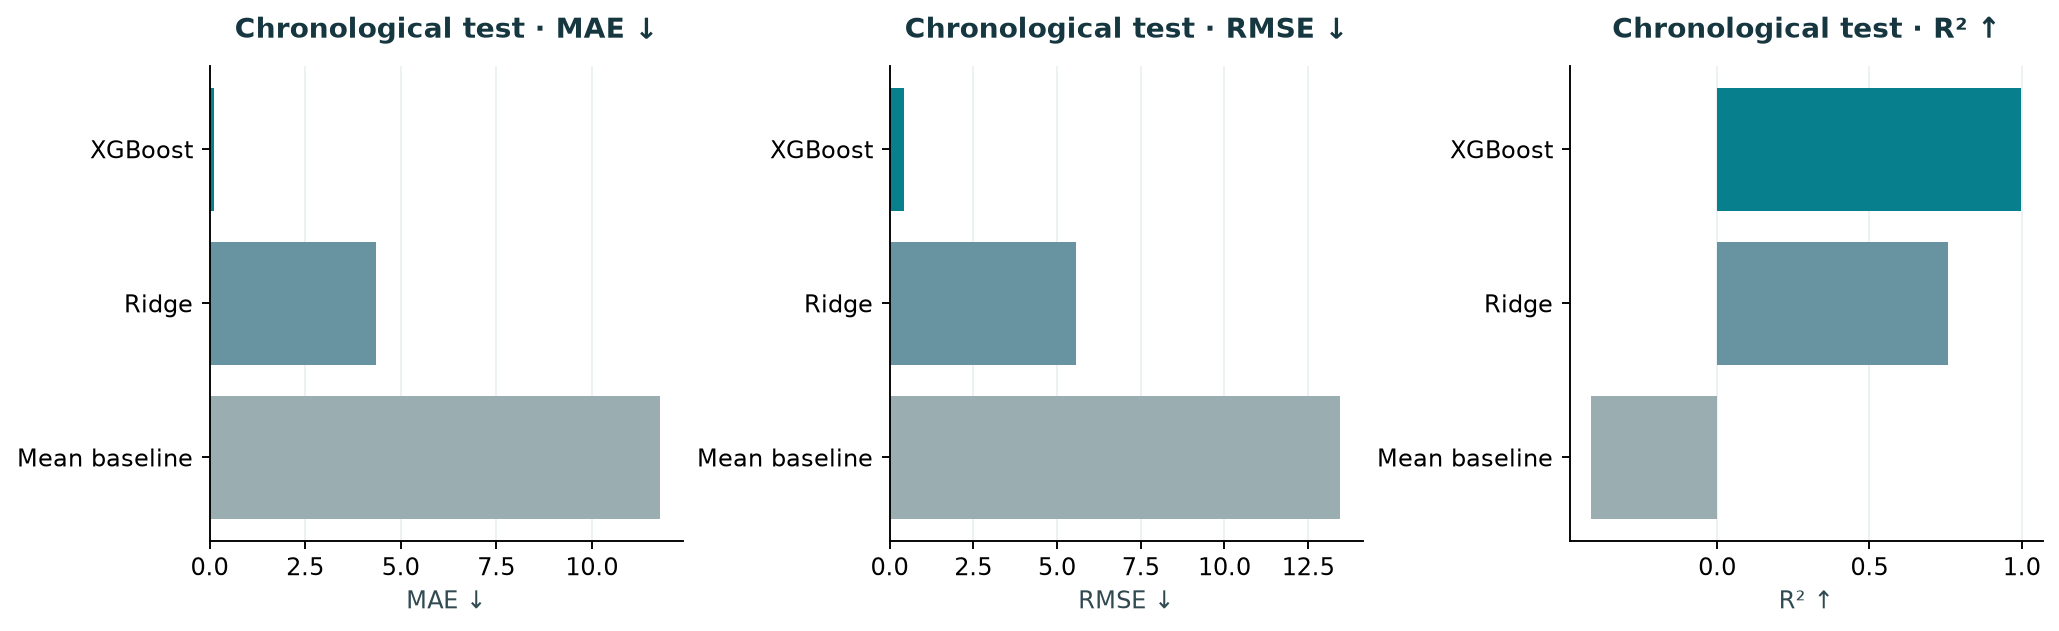

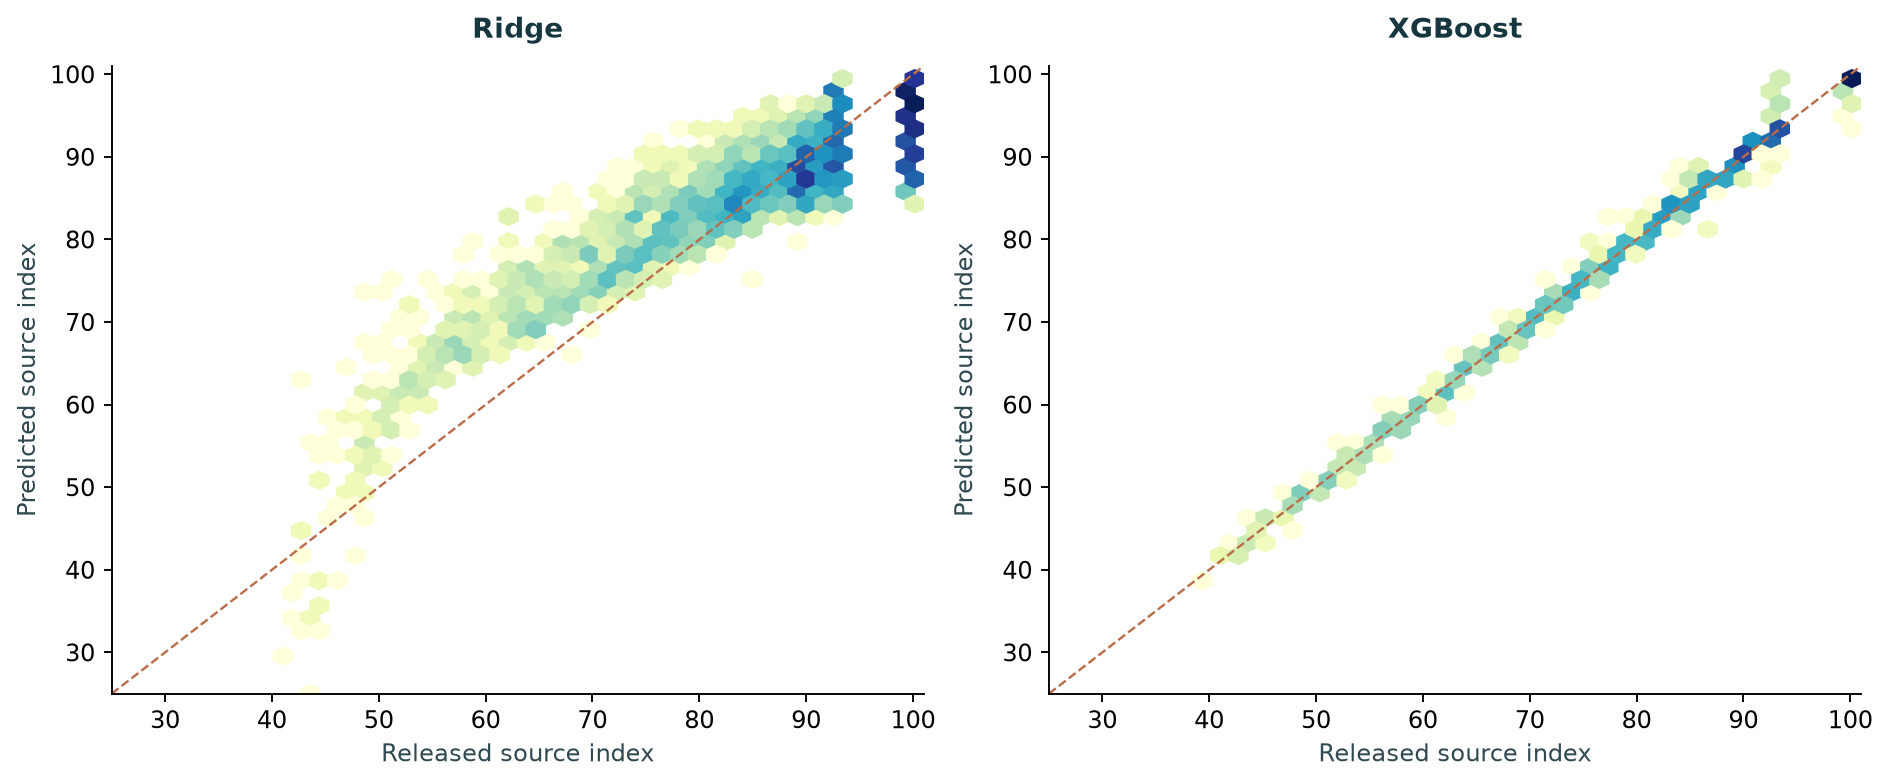

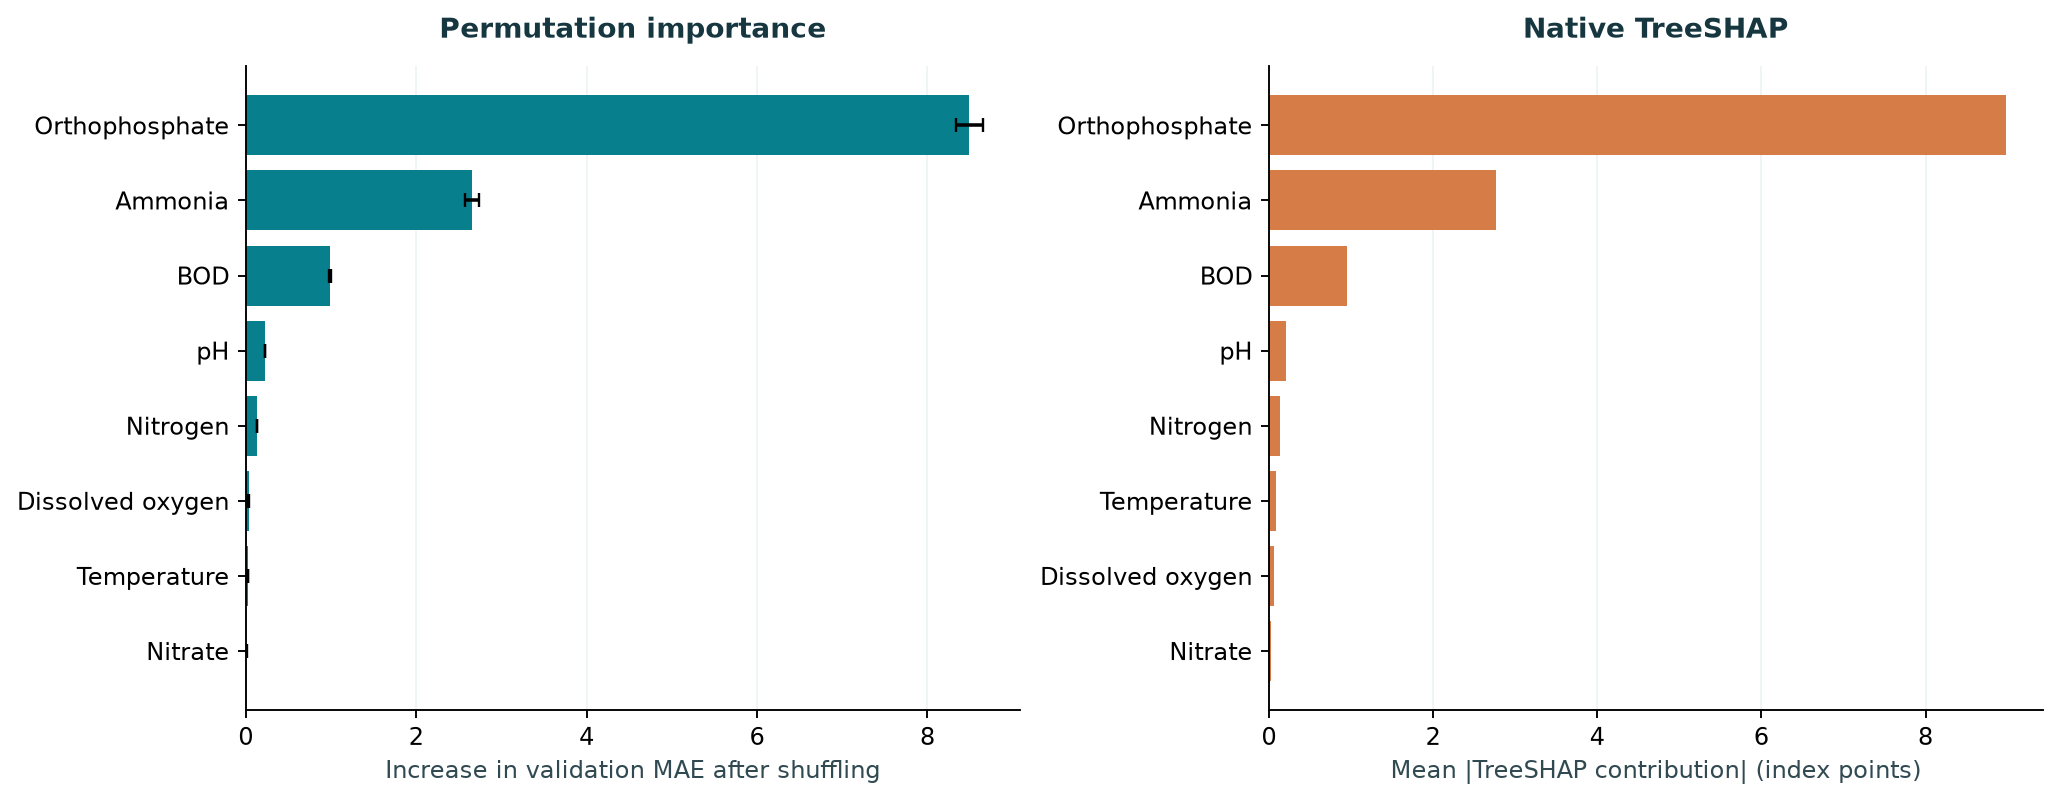

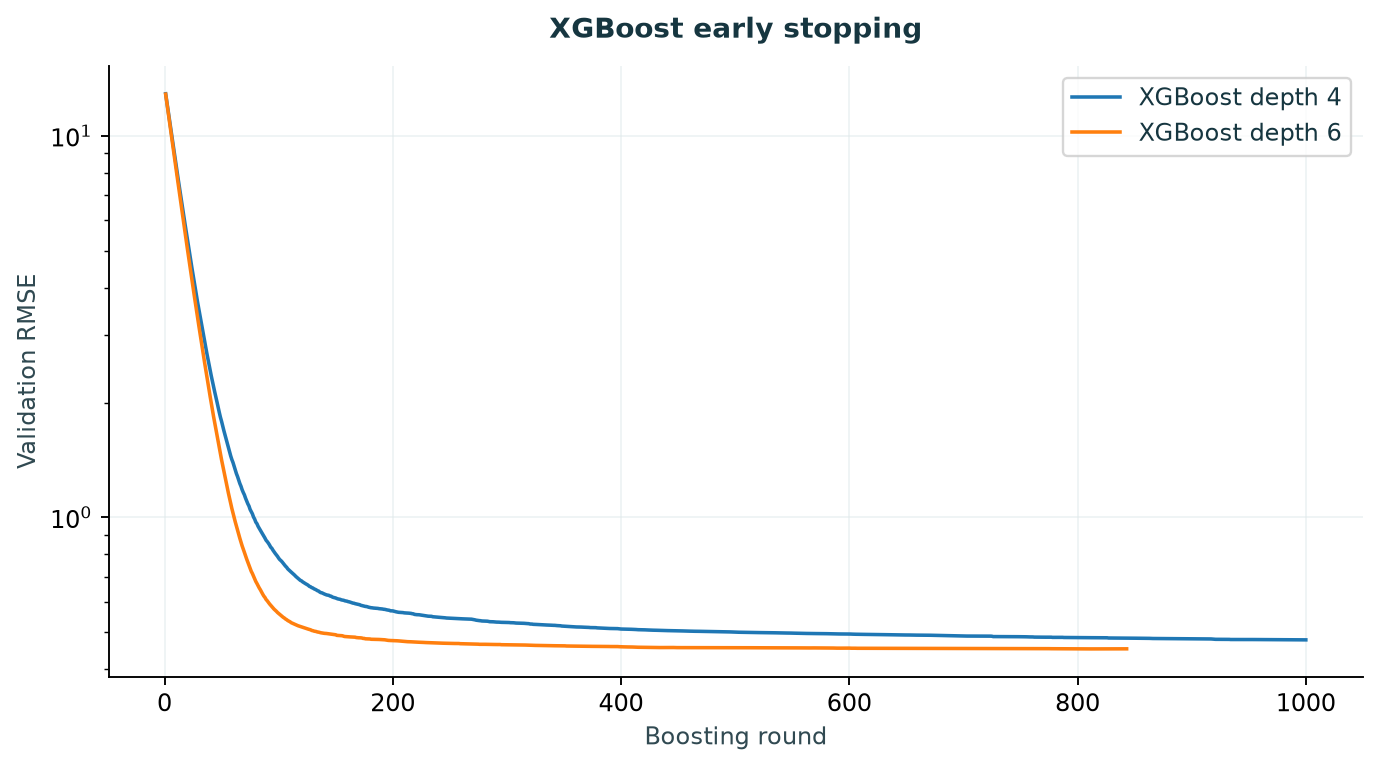

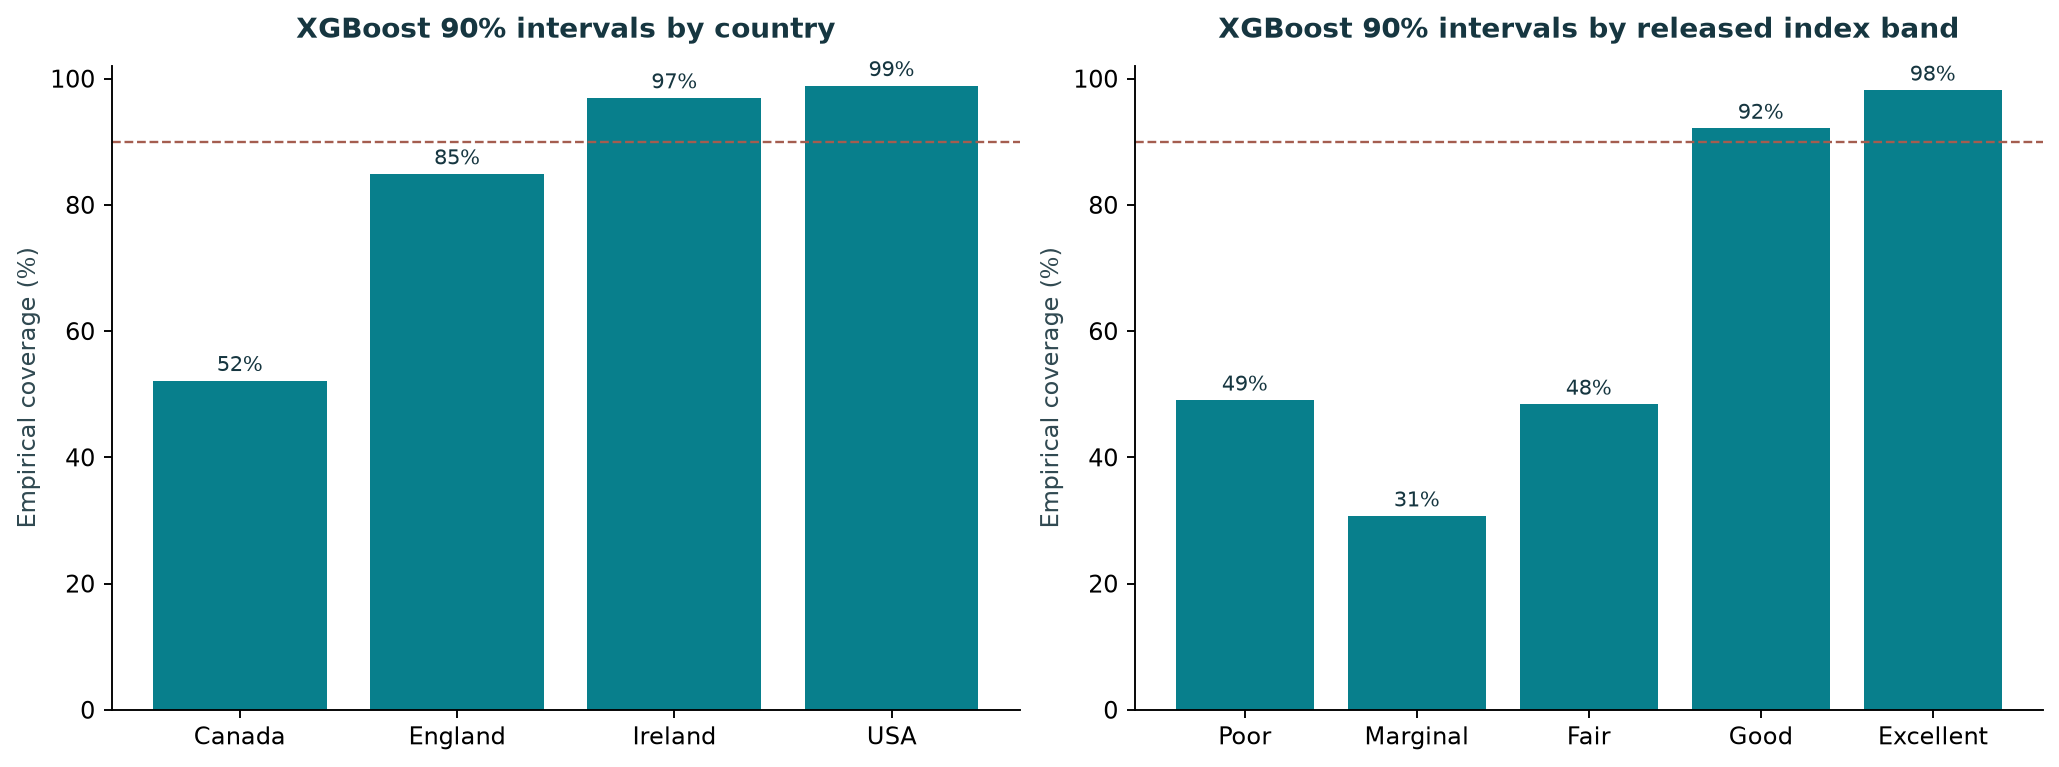

,model,mae,rmse,r2,coverage,mean_width,validation_rmse
0,Mean baseline,11.79094,13.45838,-0.41409,0.94477,31.74577,13.46159
1,Ridge,4.34415,5.56755,0.75800,0.84231,13.95585,5.56767
2,XGBoost,0.10993,0.42620,0.99858,0.88402,0.30734,0.45203


In [8]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#314a52", "text.color": "#163640",
                     "axes.titleweight": "bold", "axes.titlepad": 12,
                     "grid.color": "#dfe9ea", "axes.axisbelow": True})

def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

COLORS = {"Mean baseline": "#9aaeb2", "Ridge": "#6893a1", "XGBoost": "#087f8c"}
scores = pd.read_csv(RESULTS / "metrics.csv")
groups = pd.read_csv(RESULTS / "subgroup_metrics.csv")
importance = pd.read_csv(RESULTS / "permutation_importance.csv")
shap_table = pd.read_csv(RESULTS / "shap_importance.csv")
histories = json.loads((RESULTS / "training_history.json").read_text())
predictions = pd.read_csv(RESULTS / "predictions_test.csv.gz")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, metric, label in zip(axes, ["mae", "rmse", "r2"], ["MAE ↓", "RMSE ↓", "R² ↑"]):
    ax.barh(scores.model, scores[metric], color=[COLORS[n] for n in scores.model])
    ax.set(xlabel=label, title=f"Chronological test · {label}")
    ax.grid(axis="x", alpha=0.6)
show_figure(fig, "model_comparison.png")

plot_data = predictions.sample(n=min(7000, len(predictions)), random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
for ax, name in zip(axes, ["Ridge", "XGBoost"]):
    ax.hexbin(plot_data[TARGET], plot_data[name], gridsize=45, bins="log", cmap="YlGnBu",
              mincnt=1, extent=(25, 101, 25, 101))
    ax.plot([25, 101], [25, 101], color="#b96c47", linestyle="--", linewidth=1)
    ax.set(xlabel="Released source index", ylabel="Predicted source index", title=name,
           xlim=(25, 101), ylim=(25, 101))
show_figure(fig, "actual_vs_predicted.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
part = importance.sort_values("mae_increase")
axes[0].barh(part.feature, part.mae_increase, xerr=part.repeat_std, color="#087f8c", capsize=3)
axes[0].set(xlabel="Increase in validation MAE after shuffling", title="Permutation importance")
part = shap_table.sort_values("mean_absolute_shap")
axes[1].barh(part.feature, part.mean_absolute_shap, color="#d57c47")
axes[1].set(xlabel="Mean |TreeSHAP contribution| (index points)", title="Native TreeSHAP")
for ax in axes:
    ax.grid(axis="x", alpha=0.5)
show_figure(fig, "feature_importance.png")

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
for name, history in histories.items():
    ax.plot(np.arange(len(history)) + 1, history, label=name.replace("_", " "))
ax.set(xlabel="Boosting round", ylabel="Validation RMSE", title="XGBoost early stopping", yscale="log")
ax.legend(); ax.grid(alpha=0.5)
show_figure(fig, "learning_curves.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
for ax, group_type, title in zip(axes, ["country", "source_index_band"], ["by country", "by released index band"]):
    part = groups[(groups.group_type == group_type) & (groups.model == "XGBoost")]
    order = sorted(part.group) if group_type == "country" else [b for b in BANDS if b in set(part.group)]
    part = part.set_index("group").reindex(order)
    ax.bar(part.index, part.coverage * 100, color="#087f8c")
    ax.axhline(90, color="#a45d4f", linestyle="--", linewidth=1)
    ax.set(ylabel="Empirical coverage (%)", ylim=(0, 102), title=f"XGBoost 90% intervals {title}")
    for i, value in enumerate(part.coverage * 100):
        ax.text(i, value + 1.5, f"{value:.0f}%", ha="center", fontsize=9)
show_figure(fig, "interval_coverage.png")

display(scores[["model", "mae", "rmse", "r2", "coverage", "mean_width", "validation_rmse"]].round(5))

## 9. Predict using the reloaded model
This cell reloads the saved files, verifies their checksums and predicts five held-out examples, which must match the saved predictions. For your own CSV, keep the eight original column headers and units.

In [9]:
metadata = json.loads((MODELS / "metadata.json").read_text())
for filename, expected_hash in json.loads((MODELS / "checksums.json").read_text()).items():
    assert sha256(MODELS / filename) == expected_hash, f"Changed model file: {filename}"
preprocessors = joblib.load(MODELS / "preprocessing.joblib")  # load joblib only from trusted sources
xgb_saved = XGBRegressor()
xgb_saved.load_model(MODELS / "xgboost.json")

def predict_measurements(frame):
    """Input headers/units must match the dataset; output is the source index (0-100)."""
    features = quality_features(frame)
    prediction = np.clip(xgb_saved.predict(preprocessors["tree"].transform(features)), 0, 100)
    low, high = intervals(prediction, metadata["radii"]["XGBoost"])
    return pd.DataFrame({"XGBoost": prediction, "lower_90": low, "upper_90": high,
                         "flagged_inputs": features.iloc[:, 8:].sum(axis=1).to_numpy()}, index=frame.index)

example = pd.read_csv(RESULTS / "Example/measurements.csv")
expected = pd.read_csv(RESULTS / "Example/expected_predictions.csv")
result = predict_measurements(example)
display(pd.concat([example, result], axis=1))
np.testing.assert_allclose(result["XGBoost"], expected["XGBoost"], rtol=0, atol=1e-4)
print("Reloaded-model predictions match the saved holdout examples.")
# new_readings = pd.read_csv("your_measurements.csv")
# predict_measurements(new_readings)

,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),XGBoost,lower_90,upper_90,flagged_inputs
0,0.098000,2.7,9.040000,0.144000,7.95,14.0000,5.00,4.500,89.641640,89.443863,89.839417,0.0
1,0.030000,2.7,10.200000,0.010000,7.78,9.4000,0.71,0.706,99.999184,99.801407,100.000000,0.0
2,0.062000,2.7,8.830000,0.290000,7.81,16.4000,1.80,1.770,81.948250,81.750473,82.146027,0.0
3,0.500000,2.7,10.200000,0.700000,7.78,11.4600,18.00,4.500,69.281456,69.083679,69.479233,0.0
4,0.016667,1.4,11.684103,0.019625,8.00,8.1375,0.22,1.300,99.996292,99.798515,100.000000,0.0


Reloaded-model predictions match the saved holdout examples.


## Interpretation and limitations
XGBoost is far stronger than the mean and Ridge baselines on the 2021–2023 holdout. All released labels reconstruct from the same eight inputs, so the high R² establishes index emulation; the transparent formula is preferable when all original components are available.

Upstream imputation and uncertain unit conversion cannot be undone. England dominates the data, about 86% of test rows come from historical sites, China has no test rows and Canada has very few. Overall interval coverage hides poor coverage in the Marginal and Poor bands. The model makes no drinking-water safety decision.

The neural-network counterpart is in `DL/`.

Sources: [Figshare dataset](https://doi.org/10.6084/m9.figshare.27800394.v2), [CCME manual](https://ccme.ca/en/res/wqimanualen.pdf), [XGBoost](https://doi.org/10.1145/2939672.2939785), [Conformal prediction](https://arxiv.org/abs/2107.07511).